# Qwen: context, caching, concurrency and precision

**You are here → 01 — Qwen: caching and quantization.**

**Main workflow:** understand a local AI request → optimize Qwen → optimize Nemotron.
**Optional extensions:** model-specific NIM deployment; separate CPU portability branch.

| **Step** | **Notebook** | **Purpose** |
|---|---|---|
| 0. Understand the request | [00 — How a local AI request works](00_local_serving.ipynb) | Follow a question through schema context, model serving and generated SQL, then evaluate the results to establish a quality baseline. |
| **→ 1. Qwen optimization (current)** | [01 — Qwen: caching and quantization](01_qwen_optimization.ipynb) | Compare FP16/AWQ W4A16 and prefix caching, with cold and warm requests reported separately. |
| 2. Nemotron optimization | [02 — Nemotron optimization](02_nemotron_optimization.ipynb) | Test schema context, supported prefix caching, concurrent requests, scheduler capacity and output budgets. |
| 3. Qwen NIM (optional) | [03 — Qwen through NIM](03_qwen_nim.ipynb) | Deploy Qwen in a container, check the plan format, and compare schema context and concurrent requests. |
| 4. Nemotron NIM (optional) | [04 — Nemotron through NIM](04_nemotron_nim.ipynb) | Deploy the hybrid model through NIM and compare schema context and request concurrency. |
| 5. CPU portability (optional) | [05 — Qwen with ExecuTorch](05_edge_portability_executorch.ipynb) | Follow Qwen3-4B conversion and CPU export, then inspect a generated SQL answer and its timing. |
| 6. Compatibility study (optional) | [06 — Nemotron with ExecuTorch](06_nemotron_executorch.ipynb) | Check whether the installed exporter accepts Nemotron and identify what a working port still needs. |

We compare FP16 and AWQ W4A16 weights, each with prefix caching off and on. Caching reuses computation for shared instructions and schema; AWQ compresses weights while keeping activations at FP16. We then test schema context, concurrency, scheduling capacity, reasoning and output limits against the FP16 cache-off baseline.

The workload is structured clinical-trial questions on synthetic data with no personally identifiable information (PII). We compare response time with executed SQL and reference-result matches.

Configure your GPU environment below, then run the cells in order to collect new measurements. Each experiment saves its results separately. Completed outputs are visible when a live execution has been saved. Full request and result records are linked from each experiment.

Follow [SETUP.md](../SETUP.md) and [the execution guide](../tutorial/RUN_ALL.md) first. The target is **Qwen3-4B**, `Qwen/Qwen3-4B`, on a **Linux NVIDIA GPU**. Model loading and server startup happen before request timing.


## 1. Imports and editable configuration

`MODE` controls execution: **live** collects new inference; **plan** previews commands; **replay** explicitly reads archived results. It overrides an older local JSON mode. CPU validation supplies `LOCAL_AI_LAB_MODE=plan` or `replay` before executing these cells.

Keep machine paths, exact checkpoint revisions and deployment settings in the per-notebook local JSON. Downloads are opt-in. Remove the obsolete `execute` flag; mode is the execution authority.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/clinical_trial_mvp').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import JSON, Markdown, display
from clinical_trial_mvp.tutorial.workflow import Study, read_config
from clinical_trial_mvp.tutorial.teaching import server_example, request_example, response_example, interpret

MODE = "live"  # "plan" previews commands; "replay" displays archived results
MODE = os.environ.get('LOCAL_AI_LAB_MODE', MODE)  # Explicit CPU validation override.
CONFIG = read_config('vllm', 'qwen', root=ROOT, mode=MODE)
# Edit CONFIG here or the matching tutorial/config/*.local.json before continuing.
if 'study' in globals():
    study.close()
study = Study('vllm', 'qwen', root=ROOT, config=CONFIG, mode=MODE)
results = study.results
print('Effective mode:', study.mode)
print('Model:', 'Qwen/Qwen3-4B')
print('Hardware target: Linux / NVIDIA GPU; actual device checked next')
print('Session:', study.session_id)
print('Current-session measurements:', len(results))


Effective mode: live
Model: Qwen/Qwen3-4B
Hardware target: Linux / NVIDIA GPU; actual device checked next
Session: 20261110T233252-f6e2bc4728
Current-session measurements: 0


## 2. Preflight checks

Check the GPU, selected runtime, checkpoint paths/revisions and port 8000 before loading a model. NIM also checks Docker access, an already available image, GPU access from that image and your selected profile. Missing prerequisites stop with instructions; no package installation or image pull is automatic.


In [2]:
display(JSON(study.preflight()))


<IPython.core.display.JSON object>

## 3. Model preparation and compatibility smoke

Preparation validates local checkpoint identity and precision. It downloads weights only when `download_models=true`. NIM verifies the selected profile against discovery for this deployment.

Qwen's vLLM study requires a successful AWQ SQL smoke before all four variants. Nemotron core needs no AWQ checkpoint: its optional stretch remains separate. NIM smoke tests both serving and SQL execution; a failed required smoke blocks dependent experiments.


In [3]:
print(study.prepare())


Validated local checkpoint/configuration; ready to run.


In [4]:
smoke = study.smoke()
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(smoke)))


Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3c8fe7be.log


| Result | Status | SQL executed | Reference match | TTFT (s) | Request / inference (s) | Model load (s) | Peak memory (GiB) | Artifacts (MiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | completed | Yes | Yes | 2.684 | 4.599 | — | — | — |

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json).

## 4. Individual experiments

For the first four precision/cache variants, hold the schema, four questions, seed 42, temperature 0, output cap 1,024, scheduling capacity 4 and context limit 8,192 fixed. Subsequent experiments each change one control from fp16_cache_off; capacity experiments keep concurrency at four clients. Compare capacity 1/2/4 using batch_capacity_1, batch_capacity_2 and concurrency_4. AWQ W4A16 changes weight storage, not KV-cache precision.

Cache-on targets use **reset → cold target → reset → different-question prime → identical target warm**, with an identical shared schema prefix. Cold and warm requests remain separate. Startup, readiness, warmup, reset, priming and SQL scoring are outside individual request timing.

Predict whether shared-prefix reuse helps TTFT more than complete-request latency. Each cell below starts its own server, makes new inference requests in Live mode, saves a new result and stops that server.

| Control | What it changes |
|---|---|
| Schema context | Compare the full schema with a smaller retrieved selection. |
| Prefix caching | Reuse processing of an identical shared schema prefix; report cold and warm requests separately. |
| Concurrency | Change how many client requests overlap: 1, 2 or 4. |
| Scheduling capacity | Allow 1, 2 or 4 sequences in the server scheduler, keeping four client requests concurrent; actual batch occupancy is not measured. |
| Reasoning | Compare reasoning disabled and enabled; reasoning tokens count within the output budget. |
| Output limit | Cap generated tokens at 256, 1,024 or 2,048; the context-window limit remains 8,192. |
| Precision | Compare FP16 with validated AWQ 4-bit weights and FP16 activations (W4A16). |


### fp16 cache off

Establish the Qwen FP16 baseline with prefix caching disabled, one client, scheduling capacity 4 and an output limit of 1,024 tokens.


In [5]:
result = study.run('fp16_cache_off')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'fp16_cache_off')))


Starting fp16_cache_off | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-95ff2940.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/fp16_cache_off | completed | 3/4 | 2/4 | 2.048 / 2.051 | 6.081 / 7.647 | 12.836 / 15.095 | 23.966 | 13.950 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json).

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.081/7.647 s; aggregate output: 23.966 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### Inspect the serving call and answer

The experiment above calls the model through the OpenAI-compatible `/v1/chat/completions` API. Inspect the launch command, request, generated plan/SQL and execution checks below. The request is constructed from the experiment prompt, schema profile and generation settings. In Plan, these details preview the configured call. The response shows the generated answer and its reference-result check.

[Request transport](../src/clinical_trial_mvp/serving/client.py) · [plan and SQL execution](../src/clinical_trial_mvp/serving/agent.py)


In [6]:
display(JSON(server_example(study, 'fp16_cache_off')))
display(JSON(request_example(study, 'fp16_cache_off')))
display(JSON(response_example(study, 'fp16_cache_off')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

### fp16 cache on

Change only prefix caching from fp16_cache_off; compare cold and warm requests using an identical shared schema prefix.


In [7]:
result = study.run('fp16_cache_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'fp16_cache_on')))


Starting fp16_cache_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-de489b48.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/fp16_cache_on | completed | 3/4 | 2/4 | 0.077 / 0.102 | 4.068 / 5.706 | 8.981 / 10.371 | 34.561 | 14.544 |
| cold | completed | 15/20 | 10/20 | 2.024 / 2.028 | 6.064 / 7.643 | — | 24.015 | 14.542 |
| warm | completed | 15/20 | 10/20 | 0.080 / 0.099 | 4.053 / 5.701 | — | 34.607 | 14.542 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json).

**Prediction:** Shared-prefix reuse should reduce warm prefill latency more than total generation time.

**Observation:** Cold → warm TTFT p50: 2.024 → 0.080 s. Request E2E p50: 6.064 → 4.053 s. Direct SQL result match: 10/20 cold; 10/20 warm.

**Explanation:** The paired phase records are consistent with avoiding repeated prefill; generation still consumes time.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Consider caching for repeated schema/system prefixes after checking both phase quality counts.

### awq w4a16 cache off

Change only precision from fp16_cache_off to AWQ W4A16, after the checkpoint passes its compatibility smoke.


In [8]:
result = study.run('awq_w4a16_cache_off')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'awq_w4a16_cache_off')))


Starting awq_w4a16_cache_off | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-8f23eae0.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | completed | 3/4 | 2/4 | 2.108 / 2.118 | 4.327 / 5.133 | 9.780 / 12.258 | 33.924 | 14.569 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json).

**Prediction:** Four-bit weights reduce weight storage; latency and SQL quality may change in either direction.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 4.327/5.133 s; aggregate output: 33.924 tok/s.

**Explanation:** Quantization changes weight representation and kernel behavior; caching addresses prefix reuse.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Benchmark compatible AWQ when weight capacity matters; no native VRAM reduction is established here.

### awq w4a16 cache on

Change only prefix caching from awq_w4a16_cache_off; report cold and warm requests separately.


In [9]:
result = study.run('awq_w4a16_cache_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'awq_w4a16_cache_on')))


Starting awq_w4a16_cache_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-3bb812f2.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_on | completed | 3/4 | 2/4 | 0.053 / 0.088 | 2.279 / 3.077 | 5.896 / 7.805 | 62.682 | 14.573 |
| cold | completed | 20/20 | 15/20 | 2.093 / 2.098 | 4.308 / 5.118 | — | 34.063 | 14.569 |
| warm | completed | 20/20 | 15/20 | 0.057 / 0.075 | 2.275 / 3.086 | — | 62.622 | 14.569 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json).

**Prediction:** Shared-prefix reuse should reduce warm prefill latency more than total generation time.

**Observation:** Cold → warm TTFT p50: 2.093 → 0.057 s. Request E2E p50: 4.308 → 2.275 s. Direct SQL result match: 15/20 cold; 15/20 warm.

**Explanation:** The paired phase records are consistent with avoiding repeated prefill; generation still consumes time.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Consider caching for repeated schema/system prefixes after checking both phase quality counts.

### schema retrieved

Replace the full schema with retrieved schema context while keeping the FP16 baseline settings fixed.


In [10]:
result = study.run('schema_retrieved')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'schema_retrieved')))


Starting schema_retrieved | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-b4c5f362.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/schema_retrieved | completed | 3/4 | 2/4 | 0.194 / 0.240 | 2.652 / 3.153 | 7.386 / 9.383 | 40.383 | 14.390 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json).

**Prediction:** Less context may reduce input work but can remove definitions required for correct SQL.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 2.652/3.153 s; aggregate output: 40.383 tok/s. Baseline application result match: 2/4.

**Explanation:** Context reduction changes the information available to the model, not just compute cost.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Retain needed clinical definitions; accept reduced context only with adequate task quality.

### concurrency 2

Send two overlapping client requests while keeping server scheduling capacity at 4; compare with the one-client FP16 baseline.


In [11]:
result = study.run('concurrency_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_2')))


Starting concurrency_2 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-1d4753a2.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/concurrency_2 | completed | 3/4 | 2/4 | 2.095 / 4.032 | 8.479 / 12.778 | 12.415 / 15.014 | 32.185 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 8.479/12.778 s; aggregate output: 32.185 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### concurrency 4

Send four overlapping client requests with scheduling capacity 4; this also supplies the capacity-4 comparison for the next two experiments.


In [12]:
result = study.run('concurrency_4')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_4')))


Starting concurrency_4 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-dd967003.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/concurrency_4 | completed | 3/4 | 2/4 | 2.151 / 6.692 | 13.981 / 19.357 | 12.382 / 14.991 | 38.795 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 13.981/19.357 s; aggregate output: 38.795 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 1

Keep four clients concurrent but limit scheduling capacity to 1; compare with batch_capacity_2 and concurrency_4 (capacity 4).


In [13]:
result = study.run('batch_capacity_1')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_1')))


Starting batch_capacity_1 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-68fbf2bf.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/batch_capacity_1 | completed | 3/4 | 2/4 | 20.967 / 21.760 | 25.280 / 25.307 | 12.397 / 14.954 | 23.851 | 13.962 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 25.280/25.307 s; aggregate output: 23.851 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### batch capacity 2

Keep four clients concurrent but limit scheduling capacity to 2; compare capacity 1 → 2 → 4, without assuming achieved batch size.


In [14]:
result = study.run('batch_capacity_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'batch_capacity_2')))


Starting batch_capacity_2 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-d9909973.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/batch_capacity_2 | completed | 3/4 | 2/4 | 10.883 / 12.876 | 17.887 / 22.177 | 12.346 / 14.929 | 32.282 | 13.952 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json).

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 17.887/22.177 s; aggregate output: 32.282 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### reasoning on

Enable reasoning while holding the FP16 baseline settings and 1,024-token output limit fixed; TTFT includes reasoning and truncation remains a failure.


In [15]:
result = study.run('reasoning_on')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'reasoning_on')))


Starting reasoning_on | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-f0b508a0.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/reasoning_on | completed | 0/4 | 0/4 | 2.046 / 2.057 | 24.437 / 30.264 | 18.466 / 31.541 | 13.298 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json).

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 0/4; SQL executed: 0/4. Request E2E p50/p95: 24.437/30.264 s; aggregate output: 13.298 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 256

Reduce only the FP16 baseline output limit from 1,024 to 256 generated tokens; keep the context-window limit at 8,192.


In [16]:
result = study.run('output_256')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_256')))


Starting output_256 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-7b0759e7.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/output_256 | completed | 3/4 | 2/4 | 2.054 / 2.061 | 6.099 / 7.679 | 12.389 / 15.018 | 23.871 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json).

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.099/7.679 s; aggregate output: 23.871 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

### output 2048

Increase only the FP16 baseline output limit from 1,024 to 2,048 generated tokens; keep the context-window limit at 8,192.


In [17]:
result = study.run('output_2048')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'output_2048')))


Starting output_2048 | session 20261110T233252-f6e2bc4728
Starting vLLM; waiting for readiness. Log: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fc9cdadf.log


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/output_2048 | completed | 3/4 | 2/4 | 2.059 / 2.066 | 6.108 / 7.694 | 12.400 / 15.048 | 23.841 | 14.540 |

Memory scope: device VRAM (includes idle allocation).

| Session id | Session evidence path |
|---|---|
| 20261110T233252-f6e2bc4728 | experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json |

[Full request and result records](../experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json).

**Prediction:** Reasoning/output budgets change generation work and may affect task completion.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 6.108/7.694 s; aggregate output: 23.841 tok/s.

**Explanation:** Thoughts consume output tokens; TTFT includes thoughts, and truncated answers remain failures.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use the smallest budget that preserves required task quality; do not optimize output tok/s alone.

## 5. Current-session comparison and interpretation

Read result matches alongside latency. TTFT measures first generated content; request completion covers generation and transport; application latency includes planning, validation, execution and repair. Missing memory telemetry stays unavailable. Failed rows remain failures.

Compare cold and warm TTFT. Did any reduction carry through to complete-request latency? For concurrency, did throughput improve within your latency budget? For precision or output caps, did the amount or correctness of generated SQL change?


In [18]:
display(Markdown(study.report()))
display(Markdown(study.cache_report()))


**Mode: live · Session: 20261110T233252-f6e2bc4728**

| Configuration/status | SQL | Result match | Semantic review | Prompt tokens | TTFT p50 s | Latency p50/p95 s | tok/s | Peak memory |
|---|---|---|---|---|---|---|---|---|
| MVP4/Optimization/awq_w4a16_cache_off | 0/0 | 0/0 | Unreviewed; 0 total | — | — | —/— | — | — |
| MVP4/Optimization/fp16_cache_off | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 2.05 | 6.08/7.65 | 23.97 | 13.95 GiB |
| MVP4/Optimization/fp16_cache_on | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 0.08 | 4.07/5.71 | 34.56 | 14.54 GiB |
| MVP4/Optimization/awq_w4a16_cache_off | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 2.11 | 4.33/5.13 | 33.92 | 14.57 GiB |
| MVP4/Optimization/awq_w4a16_cache_on | 3/4 | 2/4 | Unreviewed; 4 total | 2344 | 0.05 | 2.28/3.08 | 62.68 | 14.57 GiB |
| MVP4/Optimization/schema_retrieved | 3/4 | 2/4 | Unreviewed; 4 total | — | 0.19 | 2.65/3.15 | 40.38 | 14.39 GiB |
| MVP4/Optimization/concurrency_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.10 | 8.48/12.78 | 32.19 | 14.54 GiB |
| MVP4/Optimization/concurrency_4 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.15 | 13.98/19.36 | 38.79 | 14.54 GiB |
| MVP4/Optimization/batch_capacity_1 | 3/4 | 2/4 | Unreviewed; 4 total | — | 20.97 | 25.28/25.31 | 23.85 | 13.96 GiB |
| MVP4/Optimization/batch_capacity_2 | 3/4 | 2/4 | Unreviewed; 4 total | — | 10.88 | 17.89/22.18 | 32.28 | 13.95 GiB |
| MVP4/Optimization/reasoning_on | 0/4 | 0/4 | Unreviewed; 4 total | — | 2.05 | 24.44/30.26 | 13.30 | 14.54 GiB |
| MVP4/Optimization/output_256 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.05 | 6.10/7.68 | 23.87 | 14.54 GiB |
| MVP4/Optimization/output_2048 | 3/4 | 2/4 | Unreviewed; 4 total | — | 2.06 | 6.11/7.69 | 23.84 | 14.54 GiB |

| Experiment | Application E2E p50/p95 s | Request TTFT p95 s |
|---|---|---|
| smoke | —/— | — |
| fp16_cache_off | 12.836/15.095 | 2.051 |
| fp16_cache_on | 8.981/10.371 | 0.102 |
| awq_w4a16_cache_off | 9.780/12.258 | 2.118 |
| awq_w4a16_cache_on | 5.896/7.805 | 0.088 |
| schema_retrieved | 7.386/9.383 | 0.240 |
| concurrency_2 | 12.415/15.014 | 4.032 |
| concurrency_4 | 12.382/14.991 | 6.692 |
| batch_capacity_1 | 12.397/14.954 | 21.760 |
| batch_capacity_2 | 12.346/14.929 | 12.876 |
| reasoning_on | 18.466/31.541 | 2.057 |
| output_256 | 12.389/15.018 | 2.061 |
| output_2048 | 12.400/15.048 | 2.066 |

Evidence: experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-smoke-4099eced.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_off-5d535f84.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-fp16_cache_on-9bda846e.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_off-6b17db5f.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-awq_w4a16_cache_on-cfd3066b.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-schema_retrieved-68cdec00.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_2-c96d7b06.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-concurrency_4-cf5dc2f9.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_1-92cea317.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-batch_capacity_2-97ac33b8.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-reasoning_on-0ec9803f.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_256-0a96538a.json, experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-output_2048-27af7583.json

| Variant | Phase | SQL match | Semantic | TTFT p50/p95 s | E2E p50/p95 s | TPOT p50 s | tok/s | Peak VRAM GiB |
|---|---|---|---|---|---|---|---|---|
| fp16_cache_off | cache_off | 10/20 | unreviewed | 2.010/2.016 | 6.025/7.610 | 0.028 | 24.134 | 13.950 |
| fp16_cache_on | cold | 10/20 | unreviewed | 2.024/2.028 | 6.064/7.643 | 0.028 | 24.015 | 14.542 |
| fp16_cache_on | warm | 10/20 | unreviewed | 0.080/0.099 | 4.053/5.701 | 0.028 | 34.607 | 14.542 |
| awq_w4a16_cache_off | cache_off | 15/20 | unreviewed | 2.092/2.100 | 4.307/5.114 | 0.016 | 34.070 | 14.567 |
| awq_w4a16_cache_on | cold | 15/20 | unreviewed | 2.093/2.098 | 4.308/5.118 | 0.016 | 34.063 | 14.569 |
| awq_w4a16_cache_on | warm | 15/20 | unreviewed | 0.057/0.075 | 2.275/3.086 | 0.016 | 62.622 | 14.569 |

### Check output work

Compare output tokens by phase and case before attributing latency differences to kernels or precision. Similar token counts do not establish identical SQL or computation.


In [19]:
from clinical_trial_mvp.tutorial.token_analysis import analyze, table
token_analysis = analyze(study.current_results())
display(Markdown(table(token_analysis)))


| Configuration | Phase | Requests | Mean output tokens | Median output tokens | Estimated decode tok/s p50 |
|---|---|---|---|---|---|
| FP16 | cold | 20 | 152.00 | 143.00 | 35.12 |
| FP16 | warm | 20 | 150.75 | 140.50 | 35.09 |
| AWQ W4A16 | cold | 20 | 151.50 | 143.00 | 64.09 |
| AWQ W4A16 | warm | 20 | 151.50 | 143.00 | 64.02 |

### Plot this session

The figure uses only successful measured rows selected in this session. Missing rows are not filled from another run. Plan produces no measurement figure.


Session figure: /home/setup/projects/local-ai-inference/experiment-tracker/mvp4/workflow/vllm-qwen-20261110T233252-f6e2bc4728-figure-319f06b0.png


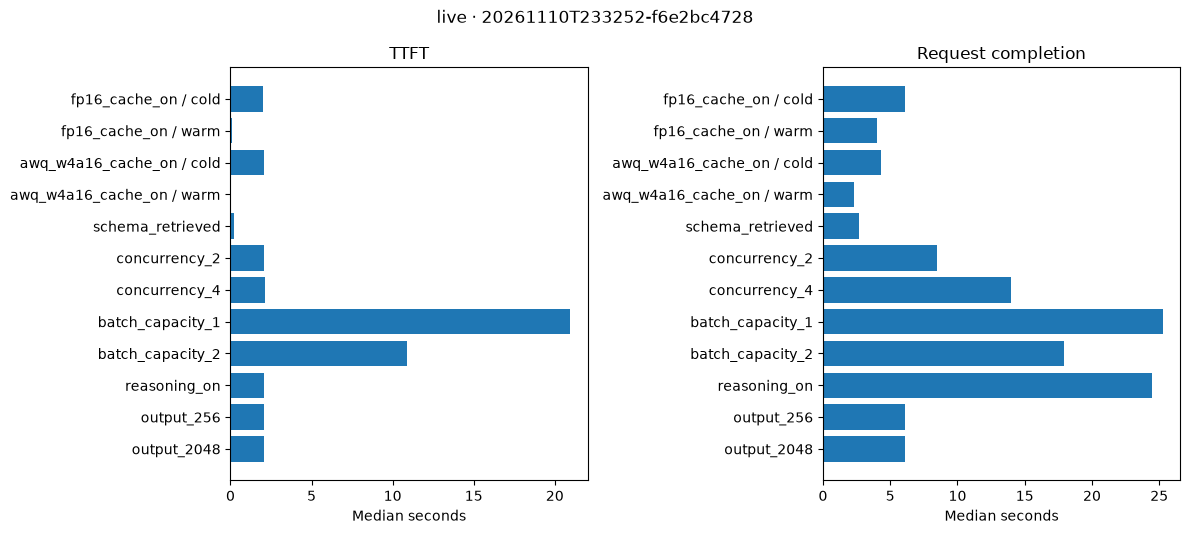

In [20]:
from clinical_trial_mvp.tutorial.session_figures import figure
fig = figure(study)
if fig is not None:
    display(fig)
    import matplotlib.pyplot as plt
    plt.close(fig)
else:
    print('No measured rows available for a figure.')


## 6. Cleanup

Save the notebook to retain Live outputs. Native servers stop after each experiment. Cleanup is safe to repeat and only stops servers started by this notebook.


In [21]:
print(study.close())


Study servers stopped. Saved records and notebook outputs are retained.
